**Обучание CNN классификатора**

Основные компоненты CNN
1) Ядро (фильтр, kernel) — маленькая матрица, обычно 3×3 или 5×5, которая скользит по изображению. (Свертка) - convolution
2) как работает свёртка:

* Накладываем ядро на левый верхний угол.
* Поэлементно умножаем и складываем — получаем одно число.
* Сдвигаем ядро на 1 пиксель вправо и повторяем.
* Продолжаем, пока не обойдём всё изображение.
в CNN ядра не задаются вручную — они обучаются! Сеть сама подбирает, какие фильтры ей нужны.
3) Далее после свертки - activation (обычно используется функция Relu)
4) Pooling (пулинг, субдискретизация)
Уменьшает размер карты признаков, сохраняя главное.
Max Pooling (самый популярный)


В конце CNN получаем — обычные полносвязные слои, которые на основе выученных признаков делают классификацию.(на выходе столько нейронов сколько классов )

In [2]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from sklearn.decomposition import FastICA
from torchvision.datasets import ImageFolder
from torchvision.models import resnet18, ResNet18_Weights

from torch.utils.data import DataLoader
import torch.optim as optim

from tqdm import tqdm  # отображать прогресс загрузки
import random
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
# sklearn - классификационные метрики (accuracy, pressision, icol, f1, rock auk)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score
from PIL import Image

%matplotlib inline

In [3]:
#Установка стилистики графиков
plt.style.use('ggplot')
plt.style.available

['Solarize_Light2',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'petroff6',
 'petroff8',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

In [4]:
# Установка Seed для воспроизводимости
# Возможность сделать повторяемость экспериментов
# На практике: для отладки и статей — фиксировать всё; для продакшена — только seed, benchmark=True для скорости.
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
np.random.seed(seed)
random.seed(seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

In [5]:
#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device('mps')   # Apple Silicon

device

device(type='mps')

In [5]:
model = resnet18(weights=ResNet18_Weights.DEFAULT)
model(torch.randn(1,3,224,224)).shape # прогоняем через нейсросетку некий случайный вектор
# #(1, 3, 224, 224)
#  │  │   │    │
#  │  │   │    └── ширина = 224 пикселя
#  │  │   └─────── высота = 224 пикселя
#  │  └─────────── каналы: 3 (RGB)
#  └────────────── batch size: 1 изображение (размер пакета - сколько кладем в пакет изображений)

torch.Size([1, 1000])

In [6]:
# Загрузим предварительно обученную модель ResNet18 - архитектура ResNet-18 (18 слоёв)
# pretrained=True - загружает ResNet18 уже со стартовыми весами
model = models.resnet18(pretrained=True)

# Заменим последний слой (fully connected) так, чтобы кол-ство выходных каналов соответствовало 3 классам
num_classes = 3
model.fc = nn.Linear(model.fc.in_features, num_classes)

/Users/chernyshov/Computer-Vision-projects/Classification pythorch by me/.venv/lib/python3.14/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/chernyshov/Computer-Vision-projects/Classification pythorch by me/.venv/lib/python3.14/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [7]:
model(torch.randn(1,3,224,224)) # прогоняем через нейсросетку некий случайный вектор


tensor([[0.1523, 0.0554, 0.4120]], grad_fn=<AddmmBackward0>)

Без особых аугментаций


 аугментации - искусственное расширение обучающего набора данных путём создания изменённых копий существующих примеров.

Проще говоря: вы берёте одну картинку кошки и делаете из неё 10 разных вариантов — повёрнутых, сдвинутых, ярких, размытых. Модель видит больше разнообразия и учится лучше.

In [7]:
# Определим путь к данным
train_data_dir='dataset/train'
val_data_dir = 'dataset/validation'

# Определим трансформации
train_transforms=transforms.Compose([ # цепочка преобразований, которые применяются последовательно к каждому изображению при загрузке.
    transforms.Resize((224,224)), # Приводит картинку к размеру 224×224 пикселя. ResNet-18 обучен на ImageNet с размером 224×224.
    transforms.ToTensor(),
])

val_transforms=transforms.Compose([
    transforms.Resize((224,224)), # тип PIL image
    transforms.ToTensor(),
])

#Создадим датасеты
train_dataset = ImageFolder(train_data_dir, transform=train_transforms)
#ImageFolder — готовый класс из torchvision.datasets, который читает картинки из папок.

val_dataset = ImageFolder(val_data_dir, transform=val_transforms)

In [9]:
train_dataset[255][0].shape


torch.Size([3, 224, 224])

In [8]:
# Создадим датагенераторы
batch_size = 64 # кол-ство картинок в пакете (батче)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True) #shuffle - перемешивание
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

Список классов:

In [9]:
classes_list = train_dataset.classes
print(classes_list)

['adidas', 'converse', 'nike']


1 Эпоха - полный прогон всего датасета через нейросетку
Если произведена 1 эпоха - значит мы прогнали все батчи которые есть
Если у нас всего 3 батча - мы за 1 эпоху прогоняем 3 батча и делаем 3 градиентных спуска

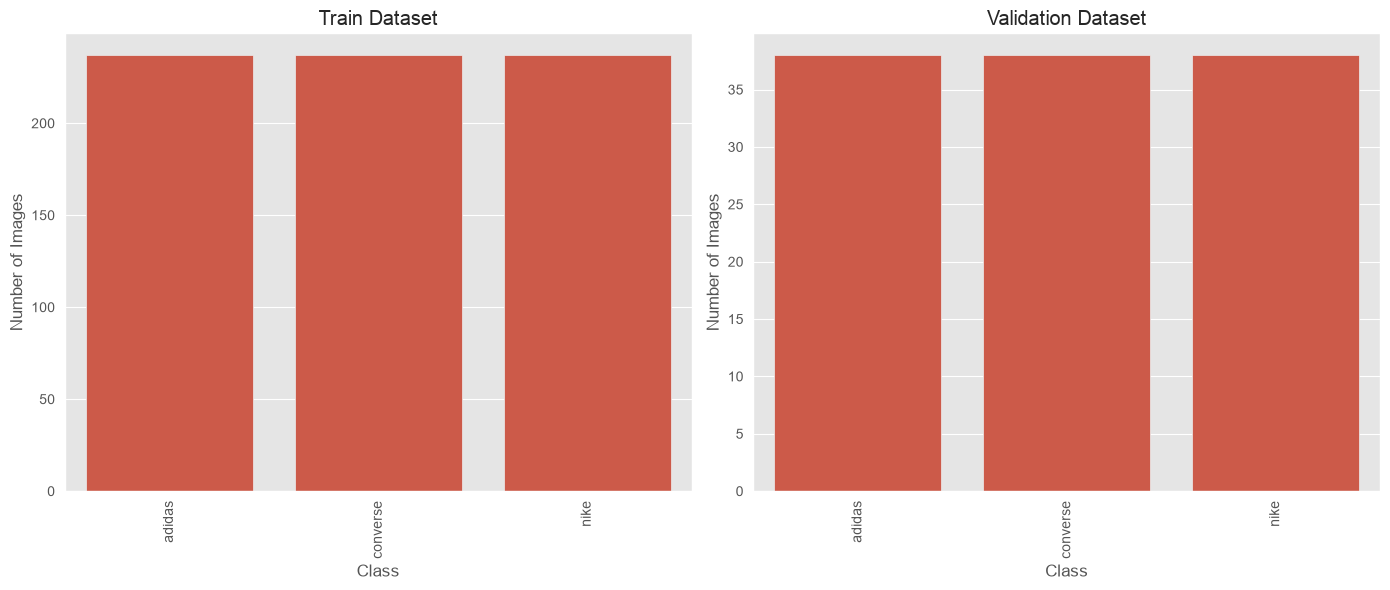

In [10]:
#Подсчитать количество изображений в каждом классе для обучающего набора данных
train_class_counts = np.zeros(len(train_dataset.classes)) # создание массива-счётчика
for _, label in train_dataset:
    train_class_counts[label] += 1

# Подсчитать количество изображений в каждом классе для валидационного набора данных
val_class_counts = np.zeros(len(val_dataset.classes))
for _, label in val_dataset:
    val_class_counts[label] += 1

#Создать barplot
fig, ax = plt.subplots(1, 2, figsize=(14,6))

# BarPlot для обучающего набора данных
sns.barplot(x=train_dataset.classes, y=train_class_counts, ax=ax[0])
ax[0].set_title('Train Dataset')
ax[0].set_xlabel('Class')
ax[0].set_ylabel('Number of Images')
ax[0].tick_params(axis='x', rotation=90)

# BarPlot для валидационного набора данных
sns.barplot(x=val_dataset.classes, y=val_class_counts, ax=ax[1])
ax[1].set_title('Validation Dataset')
ax[1].set_xlabel('Class')
ax[1].set_ylabel('Number of Images')
ax[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()


Image without normalization


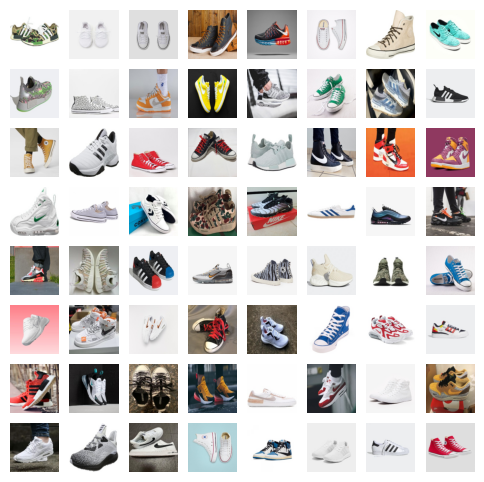

In [11]:
#Функция для отображения изображений из батча
def show_images(images, denormalize=False):
    if denormalize:
        # обратное преобразование для нормализации
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        images = images.numpy().transpose((0, 2, 3, 1))
        images = std * images + mean
        images = np.clip(images, 0, 1)
    else:
        images = images.numpy().transpose((0, 2, 3, 1))

    fig, axes = plt.subplots(8, 8, figsize=(6,6))
    for i, ax in enumerate(axes.flat):  # axes.flat «выпрямляет» его в одномерную последовательность из 64 элементов.
        ax.imshow(images[i])
        ax.axis('off')
    plt.show()

#Получение первого батча из тренировочного загрузчика данных
images, _ = next(iter(train_loader))

#Отображние изображений с восстановлением цветов
print('Image without normalization')
show_images(images, denormalize=False)

Сколько в эпохе проходов по батчам

In [14]:
len(train_loader), len(val_loader)

(12, 2)

12 - батчей в train датагенераторе (треин датасете) и 2 батча в валидейшн датагенераторе
Например если 12 батчей - то и 12 градиентных спусков за 1 эпоху

Пример данных датасета и даталоадера

In [15]:
train_dataset[0]

(tensor([[[1., 1., 1.,  ..., 1., 1., 1.],
          [1., 1., 1.,  ..., 1., 1., 1.],
          [1., 1., 1.,  ..., 1., 1., 1.],
          ...,
          [1., 1., 1.,  ..., 1., 1., 1.],
          [1., 1., 1.,  ..., 1., 1., 1.],
          [1., 1., 1.,  ..., 1., 1., 1.]],
 
         [[1., 1., 1.,  ..., 1., 1., 1.],
          [1., 1., 1.,  ..., 1., 1., 1.],
          [1., 1., 1.,  ..., 1., 1., 1.],
          ...,
          [1., 1., 1.,  ..., 1., 1., 1.],
          [1., 1., 1.,  ..., 1., 1., 1.],
          [1., 1., 1.,  ..., 1., 1., 1.]],
 
         [[1., 1., 1.,  ..., 1., 1., 1.],
          [1., 1., 1.,  ..., 1., 1., 1.],
          [1., 1., 1.,  ..., 1., 1., 1.],
          ...,
          [1., 1., 1.,  ..., 1., 1., 1.],
          [1., 1., 1.,  ..., 1., 1., 1.],
          [1., 1., 1.,  ..., 1., 1., 1.]]]),
 0)

In [16]:
next(iter(train_loader))

[tensor([[[[0.9294, 0.9294, 0.9294,  ..., 0.9294, 0.9294, 0.9294],
           [0.9294, 0.9294, 0.9294,  ..., 0.9294, 0.9294, 0.9294],
           [0.9294, 0.9294, 0.9294,  ..., 0.9294, 0.9294, 0.9294],
           ...,
           [0.9294, 0.9294, 0.9294,  ..., 0.9294, 0.9294, 0.9294],
           [0.9294, 0.9294, 0.9294,  ..., 0.9294, 0.9294, 0.9294],
           [0.9294, 0.9294, 0.9294,  ..., 0.9294, 0.9294, 0.9294]],
 
          [[0.9373, 0.9373, 0.9373,  ..., 0.9333, 0.9333, 0.9333],
           [0.9373, 0.9373, 0.9373,  ..., 0.9333, 0.9333, 0.9333],
           [0.9373, 0.9373, 0.9333,  ..., 0.9333, 0.9333, 0.9333],
           ...,
           [0.9333, 0.9333, 0.9333,  ..., 0.9333, 0.9333, 0.9333],
           [0.9333, 0.9333, 0.9333,  ..., 0.9333, 0.9333, 0.9333],
           [0.9333, 0.9333, 0.9333,  ..., 0.9333, 0.9333, 0.9333]],
 
          [[0.9255, 0.9255, 0.9333,  ..., 0.9412, 0.9412, 0.9412],
           [0.9255, 0.9255, 0.9333,  ..., 0.9412, 0.9412, 0.9412],
           [0.9333, 0.93

In [13]:
    #Валидация модели до обучения
model.eval()  #Переводит модель в режим оценки.
model.to(device)  #Переводит все параметры модели на device (CPU или GPU). или mps
correct = 0
total = 0
with torch.no_grad(): #Отключает построение графа вычислений градиентов

    for images, labels in tqdm(val_loader): #tqdm — оборачивает в прогресс-бар
        #images, labels — пара: тензор картинок (N - кол-ство картинок, 3 - каналы RGB, 224 - высота, 224 - ширина) и тензор меток (N)
        images, labels = images.to(device), labels.to(device)
        outputs = model(images) # Результат тензор формы (N - колство картинок, num_classes - кол-ство классов)/ 2 мерный массив
        print(outputs)
        _, predicted = outputs.max(1)
        #_, predicted = torch.max(outputs.data, 1)

        #значения максимума — игнорируем (_),
        #индексы максимума — это и есть предсказанный класс.
        print(predicted)
        print(labels)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        #.eq(labels) — поэлементное сравнение (eq = equal). Возвращает тензор булевых значений:
        #.sum() складывает все элементы тензора. True считается как 1, False — как 0.Результат — тензор с одним числом
        #.item() превращает тензор с одним элементом в обычное питон-число
val_accuracy = correct / total
print(val_accuracy)

NameError: name 'model' is not defined

**Обучение сети**

In [ ]:
#Определим функцию потерь и оптимизатор
criterion = nn.CrossEntropyLoss()
#1. Softmax — превращаем логиты в вероятности/
# логиты:     [2.5, -1.0]
# softmax:    [0.97, 0.03]   ← сумма = 1
#2. Negative Log-Likelihood — берём −log от вероятности правильного класса
#Затем — среднее по батчу:



optimizer = optim.Adam(model.parameters(), lr = 0.005) # Оптимизатор — алгоритм, который обновляет веса на основе градиентов.
#model.parameters()	все обучаемые параметры модели
#lr=0.005	learning rate — размер шага

#Число эпох
num_epochs = 70

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []
best_val_accuracy = 0

model.to(device) #Переносит все веса модели на устройство (mps для M1 Pro)

for epoch in range(num_epochs):
    model.train() #вкл Режим обучения
    running_loss = 0.0
    correct = 0
    total = 0
    for images, labels in tqdm(train_loader):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad() # обнуление градиентов
        outputs = model(images) # Прогоняем через нейросетку
        loss = criterion(outputs, labels) # Функция потерь — считает, насколько предсказания отличаются от истины.
        print(loss)
        loss.backward() # обратный проход (backpropagation)/ Посчитали градиенты и сделали градиентный спуск
        optimizer.step() # обновить веса

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = correct / total
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    # Валидация модели
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = correct / total
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(f'Epoch [{epoch+1}/{num_epochs}], '
          f'Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.4f}, '
          f'Val loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.4f}')

    #Сохранение лучшей модели на основе валидационной точности
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save(model.state_dict(), 'best_model.pth')
        print('Best model saved')

    # Сохранение последней актуальной модели
    torch.save(model.state_dict(), 'last_model.pth')
    print()

print('Training and validation complete')


  0%|          | 0/12 [00:00<?, ?it/s]

tensor(1.2174, device='mps:0', grad_fn=<NllLossBackward0>)


  8%|▊         | 1/12 [00:00<00:06,  1.58it/s]

tensor(1.6043, device='mps:0', grad_fn=<NllLossBackward0>)


 17%|█▋        | 2/12 [00:01<00:05,  1.90it/s]

...

 42%|████▏     | 5/12 [00:02<00:03,  2.20it/s]

tensor(1.0786, device='mps:0', grad_fn=<NllLossBackward0>)


 50%|█████     | 6/12 [00:02<00:02,  2.19it/s]

tensor(0.9200, device='mps:0', grad_fn=<NllLossBackward0>)


 58%|█████▊    | 7/12 [00:03<00:02,  2.21it/s]

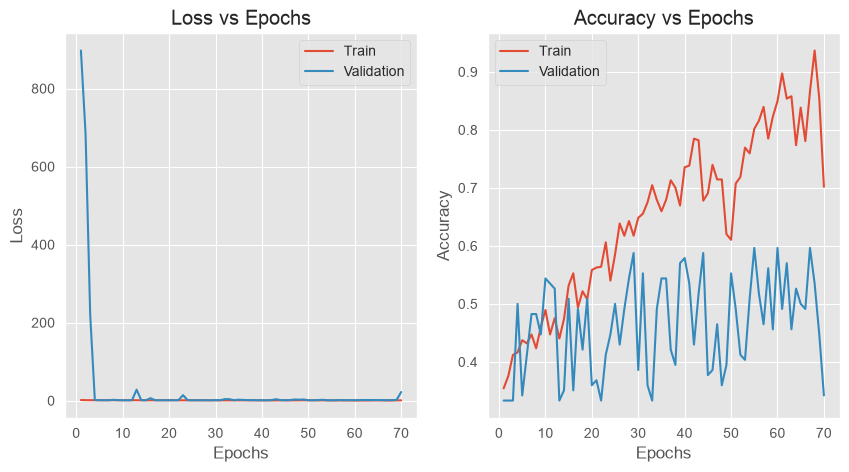

In [20]:
# Построим графики
plt.figure(figsize = (10,5))
plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs+1), train_losses, label = 'Train')
plt.plot(range(1, num_epochs+1), val_losses, label = 'Validation')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss vs Epochs')
plt.legend()

plt.subplot(1,2,2)
plt.plot(range(1, num_epochs+1), train_accuracies, label = 'Train')
plt.plot(range(1, num_epochs+1), val_accuracies, label = 'Validation')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Epochs')
plt.legend()

plt.show()

In [21]:
#Получение метрик качества для текущих весов модели
def evaluate_model(model, dataloader):
    model.eval() # режим оценки
    y_true = []
    y_pred = []
    with torch.no_grad():
        for images, labels in dataloader: #Отключает autograd — быстрее и меньше памяти.
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1) #        _, predicted = outputs.max(1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
    cm = confusion_matrix(y_true, y_pred) # Матрица ошибок
    report = classification_report(y_true, y_pred)
    accuracy = np.sum(np.diag(cm)) / np.sum(cm)

    #Вычисление взвешенной F-1 меры для текущей модели
    weighted_f1 = f1_score(y_true, y_pred, average='weighted')
    return cm, report, accuracy, weighted_f1

# Функция для построения графика матрицы ошибок
def plot_confusion_matrix(cm, classes):
    with plt.style.context('default'):
        plt.figure(figsize=(5,4))
        sns.set(font_scale=1.0)
        sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', cbar=False,
                    xticklabels=classes, yticklabels=classes)
        # cm	массив	данные для heatmap
        # annot=True	—	печатать числа внутри ячеек
        # fmt='g'	—	формат чисел (general — без лишних нулей)
        # cmap='Blues'	—	цветовая схема (синие оттенки)
        # cbar=False	—	не показывать цветовую шкалу справа
        # xticklabels=classes	список	подписи по оси X (предсказанные)
        # yticklabels=classes	список	подписи по оси Y (истинные)

        plt.xlabel('Predicted labels')
        plt.ylabel('True labels')
        plt.title('Confusion matrix')
        plt.show()


Metrix for current model:
              precision    recall  f1-score   support

           0       0.59      0.53      0.56        38
           1       0.95      0.55      0.70        38
           2       0.47      0.71      0.56        38

    accuracy                           0.60       114
   macro avg       0.67      0.60      0.61       114
weighted avg       0.67      0.60      0.61       114

Test accuracy: 0.5965


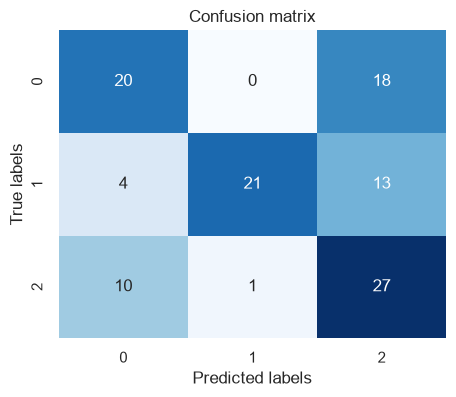

In [22]:
# Загрузка весов модели
model.load_state_dict(torch.load('best_model.pth'))
model.to(device)

#Оценка модели и построение матрицы ошибок
cm, report, accuracy_1, weighted_f1_1 = evaluate_model(model, val_loader)
print('Metrix for current model:')
print(report)
print(f'Test accuracy: {accuracy_1:.4f}')
plot_confusion_matrix(cm, classes=list(range(3))) #classes	список имён классов, например ['cats', 'dogs']


# Precision = TP / (TP + FP) «Когда модель сказала "Positive" — как часто она была права?»
# Recall	TP / (TP + FN)	«из всех настоящих nike/adidas/converse — сколько нашла»
# F1-score	2·P·R / (P+R)	баланс precision и recall
# Support	—	сколько примеров класса в датасете
# accuracy Доля правильных ответов, посчитанная из confusion matrix:Общая точность модели — доля правильных ответов среди всех примеров.
# macro avg - простое среднее по всем метрикам precision, recall, f1-score
# weighted avg - Среднее с весами по размеру класса (support).Каждый класс весит пропорционально своему размеру.

Добавим аугментаций

In [23]:
#Загрузим предварительно обученную модель
model = models.resnet18(pretrained=True)

#Заменим последний слой fully connected так, чтобы кол-ство выходных каналов соответствовало 3 классам
num_classes = 3
model.fc = nn.Linear(model.fc.in_features, num_classes)


/Users/chernyshov/Computer-Vision-projects/Classification pythorch by me/.venv/lib/python3.14/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/chernyshov/Computer-Vision-projects/Classification pythorch by me/.venv/lib/python3.14/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [34]:
# Определим пути к данным
train_data_dir = 'dataset/train'
val_data_dir = 'dataset/validation'

#Определим трансформации
train_transforms = transforms.Compose([
    transforms.Resize(256), # Приводит меньшую сторону картинки к 256 пикселям, сохраняя пропорции.
    transforms.RandomRotation(15), #Случайный поворот на угол в диапазоне [-15°, +15°].
    transforms.CenterCrop(224), #Обрезает центральную область 224×224. Зачем: получить фиксированный размер 224×224, который ожидает ResNet.
    transforms.RandomHorizontalFlip(0.5), #Горизонтальное отражение (зеркало) с вероятностью 50%.
    transforms.ToTensor(), #Превращает PIL-картинку в тензор PyTorch: (H, W, C) → (C, H, W) — каналы вперёд,
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) #Нормализует каждый канал:
    #Зачем: предобученные модели (ResNet) обучались на таких нормализованных данных. Если подать ненормализованные — точность упадёт.
])
val_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

#Создадим датасеты
train_dataset = ImageFolder(train_data_dir, transform=train_transforms)
val_dataset = ImageFolder(val_data_dir, transform=val_transforms)

#Создадим датагенераторы
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

Images without normalization:


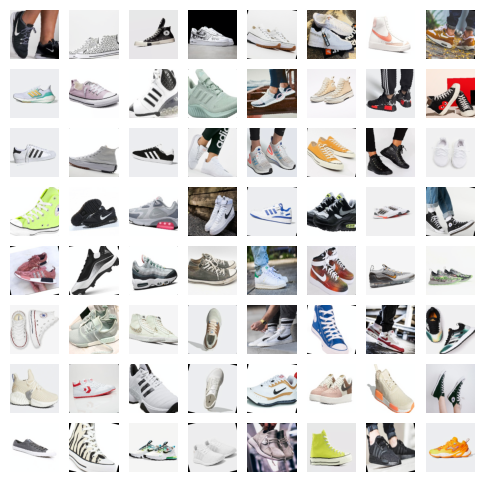

In [35]:
#Получение первого батча из тренировочного загрузчика данных

images, _ = next(iter(train_loader))

#Отображение изображений с восстановлением цветов
print('Images without normalization:')
show_images(images, denormalize=True)


Еще раз обучение

In [15]:
#Определим функцию потерь и оптимизатор
criterion = nn.CrossEntropyLoss()
#1. Softmax — превращаем логиты в вероятности/
# логиты:     [2.5, -1.0]
# softmax:    [0.97, 0.03]   ← сумма = 1
#2. Negative Log-Likelihood — берём −log от вероятности правильного класса
#Затем — среднее по батчу:



optimizer = optim.Adam(model.parameters(), lr = 0.001) # Оптимизатор — алгоритм, который обновляет веса на основе градиентов.
#model.parameters()	все обучаемые параметры модели
#lr=0.005	learning rate — размер шага

#Число эпох
num_epochs = 70

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []
best_val_accuracy = 0

model.to(device) #Переносит все веса модели на устройство (mps для M1 Pro)

for epoch in range(num_epochs):
    model.train() #вкл Режим обучения
    running_loss = 0.0
    correct = 0
    total = 0
    for images, labels in tqdm(train_loader):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad() # обнуление градиентов
        outputs = model(images) # Прогоняем через нейросетку
        loss = criterion(outputs, labels) # Функция потерь — считает, насколько предсказания отличаются от истины.
        print(loss)
        loss.backward() # обратный проход (backpropagation)/ Посчитали градиенты и сделали градиентный спуск
        optimizer.step() # обновить веса

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = correct / total
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    # Валидация модели
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = correct / total
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(f'Epoch [{epoch+1}/{num_epochs}], '
          f'Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.4f}, '
          f'Val loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.4f}')

    #Сохранение лучшей модели на основе валидационной точности
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save(model.state_dict(), 'best_model.pth')
        print('Best model saved')

    # Сохранение последней актуальной модели
    torch.save(model.state_dict(), 'last_model.pth')
    print()

print('Training and validation complete')


  0%|          | 0/12 [00:00<?, ?it/s]

tensor(1.0981, device='mps:0', grad_fn=<NllLossBackward0>)


 17%|█▋        | 2/12 [00:01<00:07,  1.39it/s]

tensor(9.5010, device='mps:0', grad_fn=<NllLossBackward0>)


 25%|██▌       | 3/12 [00:01<00:04,  2.05it/s]

...

tensor(5.2981e-05, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(3.0222e-05, device='mps:0', grad_fn=<NllLossBackward0>)


100%|██████████| 12/12 [00:02<00:00,  5.78it/s]


tensor(4.4202e-05, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(2.7570e-05, device='mps:0', grad_fn=<NllLossBackward0>)


100%|██████████| 2/2 [00:00<00:00, 10.50it/s]


Epoch [70/70], Train Loss: 0.0000, Train Accuracy: 1.0000, Val loss: 2.4723, Val Accuracy: 0.5965

Training and validation complete


Оценка качества

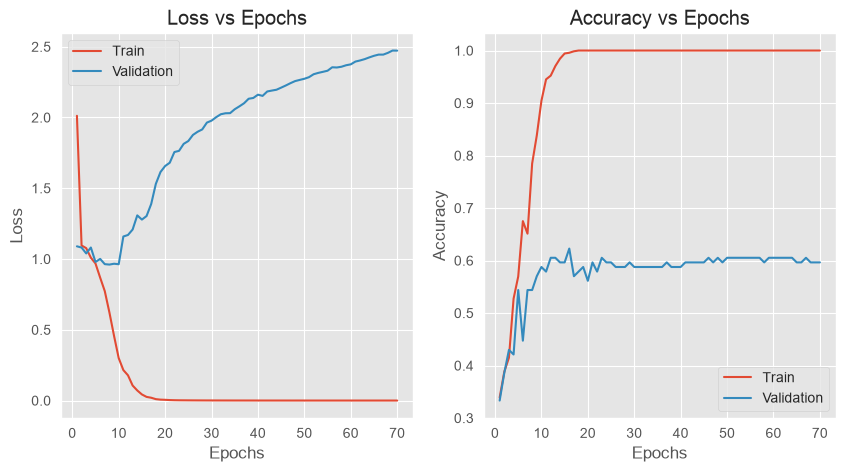

In [21]:
# Построим графики
plt.figure(figsize = (10,5))
plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs+1), train_losses, label = 'Train')
plt.plot(range(1, num_epochs+1), val_losses, label = 'Validation')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss vs Epochs')
plt.legend()

plt.subplot(1,2,2)
plt.plot(range(1, num_epochs+1), train_accuracies, label = 'Train')
plt.plot(range(1, num_epochs+1), val_accuracies, label = 'Validation')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Epochs')
plt.legend()

plt.show()

In [20]:
# Загрузка весов модели
model.load_state_dict(torch.load('best_model.pth'))
model.to(device)

#Оценка модели и построение матрицы ошибок
cm, report, accuracy_1, weighted_f1_1 = evaluate_model(model, val_loader)
print('Metrix for current model:')
print(report)
print(f'Test accuracy: {accuracy_1:.4f}')
plot_confusion_matrix(cm, classes=list(range(3))) #classes	список имён классов, например ['cats', 'dogs']


# Precision = TP / (TP + FP) «Когда модель сказала "Positive" — как часто она была права?»
# Recall	TP / (TP + FN)	«из всех настоящих nike/adidas/converse — сколько нашла»
# F1-score	2·P·R / (P+R)	баланс precision и recall
# Support	—	сколько примеров класса в датасете
# accuracy Доля правильных ответов, посчитанная из confusion matrix:Общая точность модели — доля правильных ответов среди всех примеров.
# macro avg - простое среднее по всем метрикам precision, recall, f1-score
# weighted avg - Среднее с весами по размеру класса (support).Каждый класс весит пропорционально своему размеру.

RuntimeError: Error(s) in loading state_dict for ResNet:
	Missing key(s) in state_dict: "bn1.weight", "bn1.bias", "bn1.running_mean", "bn1.running_var", "layer1.0.conv1.weight", "layer1.0.bn1.weight", "layer1.0.bn1.bias", "layer1.0.bn1.running_mean", "layer1.0.bn1.running_var", "layer1.0.conv2.weight", "layer1.0.bn2.weight", "layer1.0.bn2.bias", "layer1.0.bn2.running_mean", "layer1.0.bn2.running_var", "layer1.1.conv1.weight", "layer1.1.bn1.weight", "layer1.1.bn1.bias", "layer1.1.bn1.running_mean", "layer1.1.bn1.running_var", "layer1.1.conv2.weight", "layer1.1.bn2.weight", "layer1.1.bn2.bias", "layer1.1.bn2.running_mean", "layer1.1.bn2.running_var", "layer2.0.conv1.weight", "layer2.0.bn1.weight", "layer2.0.bn1.bias", "layer2.0.bn1.running_mean", "layer2.0.bn1.running_var", "layer2.0.conv2.weight", "layer2.0.bn2.weight", "layer2.0.bn2.bias", "layer2.0.bn2.running_mean", "layer2.0.bn2.running_var", "layer2.0.downsample.0.weight", "layer2.0.downsample.1.weight", "layer2.0.downsample.1.bias

***Инференс готовой модели***

In [19]:
#Загрузим предварительно обученную модель Resnet18
model = models.resnet18()

#Заменим последний слой fully connected так, чтобы кол-ство выходных каналов соответствовало 3 классам
num_classes = 3
model.fc = nn.Linear(model.fc.in_features, num_classes)

#Загрузка весов модели
model.load_state_dict(torch.load('best_model.pth'))
device = torch.device('cuda' if torch.cuda.is_available() else 'mps')
model.to(device)
model.eval()

# Предобработка изображения
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

RuntimeError: Error(s) in loading state_dict for ResNet:
	Missing key(s) in state_dict: "bn1.weight", "bn1.bias", "bn1.running_mean", "bn1.running_var", "layer1.0.conv1.weight", "layer1.0.bn1.weight", "layer1.0.bn1.bias", "layer1.0.bn1.running_mean", "layer1.0.bn1.running_var", "layer1.0.conv2.weight", "layer1.0.bn2.weight", "layer1.0.bn2.bias", "layer1.0.bn2.running_mean", "layer1.0.bn2.running_var", "layer1.1.conv1.weight", "layer1.1.bn1.weight", "layer1.1.bn1.bias", "layer1.1.bn1.running_mean", "layer1.1.bn1.running_var", "layer1.1.conv2.weight", "layer1.1.bn2.weight", "layer1.1.bn2.bias", "layer1.1.bn2.running_mean", "layer1.1.bn2.running_var", "layer2.0.conv1.weight", "layer2.0.bn1.weight", "layer2.0.bn1.bias", "layer2.0.bn1.running_mean", "layer2.0.bn1.running_var", "layer2.0.conv2.weight", "layer2.0.bn2.weight", "layer2.0.bn2.bias", "layer2.0.bn2.running_mean", "layer2.0.bn2.running_var", "layer2.0.downsample.0.weight", "layer2.0.downsample.1.weight", "layer2.0.downsample.1.bias

In [18]:
# Загружаем изображение для инференса
image_path = 'dataset/validation/nike/2.jpg'
image = Image.open(image_path)
image_tensor = preprocess(image)
image_tensor = image_tensor.unsqueeze_(0).to(device) #Добавляет ось батча. Модель ждёт батч (N, C, H, W), а не одну картинку.
#(3, 224, 224)  →  unsqueeze_(0)  →  (1, 3, 224, 224)
#(unsqueeze_ вместо unsqueeze) — in-place операция, изменяет тензор на месте. Экономит память, но может быть неочевидна.


# Прогоняем изображение через модель
with torch.no_grad():
    output = model(image_tensor)

print(output[0])
# Применияем softmax для получения вероятностей классов
probabilities = torch.nn.functional.softmax(output[0], dim = 0).cpu() #Превращает логиты в вероятности, сумма = 1.
#dim=0 — потому что массив output[0] — одномерный, ось одна.
print(probabilities)
# Отображение результатов
top_prob, top_class = torch.topk(probabilities, k = 1) #При k=1 — максимум и его индекс.
top_prob = top_prob.item()
top_class = top_class.item()

#Получить имя класса
class_names = ['adidas', 'converse', 'nike']
class_name = class_names[top_class]

#Отобразить изображение
plt.imshow(image)
plt.axis('off')
plt.title(f'Predicted: {class_name} ({top_prob*100:.2f}%)')
plt.show()

NameError: name 'preprocess' is not defined

In [17]:
# Построить барплот
plt.figure(figsize=(10,5))
bars = plt.bar(range(len(probabilities)), probabilities, color = 'blue')
plt.xlabel('Classes')
plt.ylabel('Probability')
plt.title('Class probabilities')
plt.xticks(range(len(probabilities)), class_names, rotation = 'vertical')

# Подсветить класс с наибольшей увереностью
bars[top_class].set_color('red')
plt.tight_layout()
plt.show()

NameError: name 'probabilities' is not defined

<Figure size 1000x500 with 0 Axes>

Своя сеть рукописная


In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):
    def __init__(self, num_classes = 3):
        super(SimpleCNN, self).__init__() # обязательный вызов, инициализирует внутренние механизмы (parameters(), state_dict(), .to(device))
        # 1 слой: свертка 3x3, 3 входных каналов, 16 выходных каналов, шаг 1:
        self.conv1 = nn.Conv2d(in_channels = 3, out_channels = 16, kernel_size = 3, stride = 1, padding = 1)
        # 2 слой: пуллинг 2х2, шаг 2:
        self.pool = nn.MaxPool2d(kernel_size = 2, stride = 2) # Max pooling 2×2 — уменьшает H и W в 2 раза.
        # 3 слой: свертка 3х3, 16 входных каналов, 32 выходных канала
        self.conv2 = nn.Conv2d(in_channels = 16, out_channels = 32, kernel_size = 3, stride = 1, padding = 1)
        # 4 слой: пуллинг 2х2 шаг 2:
        self.pool2 = nn.MaxPool2d(kernel_size = 2, stride = 2)
        # 5 слой: полносвязный слой
        self.fc1 = nn.Linear(32 * 56 * 56, 256)
        # 6 слой: полносвязный слой
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x): # x - тензор
        # слой 1
        x = F.relu(self.conv1(x))
        x = self.pool(x)
        # слой 2
        x = F.relu(self.conv2(x))
        x = self.pool2(x)

        #Преобразования в полномерный тензор для полносвязного слоя
        x = x.view(-1, 32 * 56 * 56) # -1 означает «посчитай сам»: PyTorch сам вычислит N из общего числа элементов.
        # слой 5
        x = F.relu(self.fc1(x))
        # слой 6
        x = self.fc2(x)
        return x

# Инициалзация модели
model = SimpleCNN(num_classes = 3)
print(model)



SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=100352, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=3, bias=True)
)
